# Exploração — malha de bairros e POAGEODATA

**Projeto Extensionista INCT SiMAI — Fase 2**
Gabriel Erich Franco, matrícula 25200213

Duas bases, com papéis diferentes no projeto:

| | Base | Papel |
|---|---|---|
| 3 | Malha oficial dos bairros (Prefeitura, ArcGIS REST) | a geometria dos 94 bairros |
| 4 | POAGEODATA (Zenodo, DOI 10.5281/zenodo.14807279) | população, mortalidade e as três grafias de nome |


**Rode `python scripts/coleta_bairros.py` antes deste notebook.** Ele grava o dado bruto em `dados/originais/`.

In [1]:
import json
import re
import unicodedata
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

import geopandas as gpd

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)

# Encontra a raiz do projeto, esteja o notebook aberto aqui ou na raiz.
import os
_raiz = Path.cwd()
while not (_raiz / "dados").is_dir() and _raiz != _raiz.parent:
    _raiz = _raiz.parent
if not (_raiz / "dados").is_dir():
    raise FileNotFoundError("pasta dados/ não encontrada: rode a partir do projeto")
os.chdir(_raiz)
print("raiz do projeto:", _raiz)
print("geopandas", gpd.__version__)

raiz do projeto: /home/gabriel12/Área de trabalho/PASTA_CPA/Projeto_INCT/inct_Franco/inct_gabriel
geopandas 1.2.0


## 0. A chave de junção

As duas bases se ligam por nome de bairro, e nome de bairro é o tipo de chave
que falha em silêncio: basta um acento, um apóstrofo ou um espaço a mais para
duas linhas que são o mesmo lugar deixarem de casar. A função abaixo produz a
chave, e a troca de aspas vem **antes** do `NFKD` de propósito — o acento agudo
solto (`´`, U+00B4) decompõe em espaço mais acento combinante, e `d´Areia`
viraria `D AREIA` em vez de `DAREIA`.

In [2]:
ASPAS = dict.fromkeys(map(ord, "'`´’‘ʼ\u02bc"), None)


def normaliza(nome):
    """Chave de junção: sem acento, sem pontuação, caixa alta, espaço único."""
    if nome is None or (isinstance(nome, float) and pd.isna(nome)):
        return None
    s = str(nome).replace("\u00a0", " ")
    s = s.translate(ASPAS)                      # antes do NFKD
    s = unicodedata.normalize("NFKD", s)
    s = "".join(c for c in s if not unicodedata.combining(c))
    s = re.sub(r"[^A-Z0-9 ]", " ", s.upper())
    return re.sub(r"\s+", " ", s).strip()


def chave_forte(nome):
    """Sem espaço nenhum. Não serve para juntar: serve para achar os
    quase-iguais que a chave normal deixou passar, e levar para conferência."""
    k = normaliza(nome)
    return k.replace(" ", "") if k else k


for teste in ["PASSO D'AREIA", "Passo d´Areia", "PASSO DAREIA",
              "TRÊS FIGUEIRAS", " cristal ", "Praia  de   Belas"]:
    print(f"{teste!r:<22} -> {normaliza(teste)!r}")

"PASSO D'AREIA"        -> 'PASSO DAREIA'
'Passo d´Areia'        -> 'PASSO DAREIA'
'PASSO DAREIA'         -> 'PASSO DAREIA'
'TRÊS FIGUEIRAS'       -> 'TRES FIGUEIRAS'
' cristal '            -> 'CRISTAL'
'Praia  de   Belas'    -> 'PRAIA DE BELAS'


---
# PARTE 1 — Malha oficial dos bairros

## 1.1 Leitura e descrição

In [3]:
malha = gpd.read_file("dados/originais/bairros_poa_2016.geojson")

print("feições no arquivo:", len(malha))
print("nomes distintos:   ", malha["nome"].nunique())
print("CRS:", malha.crs)
print()
print(malha.dtypes.to_string())

feições no arquivo: 128
nomes distintos:    94
CRS: EPSG:4674

objectid_1             int32
objectid               int32
nome                     str
data_edicao            int64
st_area(shape)       float64
st_length(shape)     float64
geometry            geometry


## 1.2 Uma feição não é um bairro

As duas contagens acima não batem. O serviço guarda um polígono por pedaço de
terra, então bairro com ilha ou área separada chega em várias linhas. Se eu
tratasse linha como bairro, contaria alguns deles mais de uma vez — e o erro
não apareceria em lugar nenhum até o total somado lá na frente ficar estranho.

In [4]:
pedacos = (malha.groupby("nome").size()
                .loc[lambda s: s > 1]
                .sort_values(ascending=False))

print(f"{len(pedacos)} bairros chegam partidos:\n")
print(pedacos.to_string())
print("\ngeometrias:", malha.geom_type.unique().tolist())

2 bairros chegam partidos:

nome
ARQUIPÉLAGO         34
BOA VISTA DO SUL     2

geometrias: ['Polygon']


O caso grande é o Arquipélago, que são as ilhas do delta do Jacuí. Cada ilha
virou uma linha porque a camada guarda tudo como `Polygon` e nunca como
`MultiPolygon`.

Para ter uma linha por bairro, o `dissolve` une as geometrias que dividem o
mesmo nome.

In [5]:
bairros = malha.dissolve(by="nome", as_index=False)

print("polígonos:", len(malha), "->  bairros:", len(bairros))
print("geometrias depois da união:", bairros.geom_type.value_counts().to_dict())

polígonos: 128 ->  bairros: 94
geometrias depois da união: {'Polygon': 92, 'MultiPolygon': 2}


Daqui para a frente `malha` é o arquivo como ele veio, e `bairros` é a unidade
de análise. Conta por bairro usa `bairros`; checagem de qualidade do arquivo
continua olhando `malha`.

In [6]:
malha.head(5)

,objectid_1,objectid,nome,data_edicao,st_area(shape),st_length(shape),geometry
0,2,1282,HIGIENÓPOLIS,1476921600000,0.000099,0.044077,"POLYGON ((-51.1781 -30.01961, -51.17812 -30.01..."
1,3,1283,VILA IPIRANGA,1476921600000,0.000170,0.070277,"POLYGON ((-51.14635 -30.02733, -51.1464 -30.02..."
2,4,1288,PARQUE SANTA FÉ,1476921600000,0.000162,0.049013,"POLYGON ((-51.09871 -30.0049, -51.0988 -30.004..."
3,5,1289,COSTA E SILVA,1476921600000,0.000168,0.063641,"POLYGON ((-51.10982 -30.00215, -51.11002 -30.0..."
4,6,1290,RUBEM BERTA,1476921600000,0.000253,0.101987,"POLYGON ((-51.0946 -30.02015, -51.09455 -30.02..."


## 1.3 Classificação dos atributos

Antes de calcular qualquer coisa, vale dizer o que cada coluna é. O que decide o
tratamento não é o tipo que o pandas inferiu: é o papel do campo.

| Campo | Classificação | Serve para |
|---|---|---|
| `objectid`, `objectid_1`, `id` | identificador | controle interno do ArcGIS, não é informação sobre o bairro |
| `nome` | qualitativo nominal | **a chave do projeto** |
| `data_edicao` | quantitativo intervalar (data em epoch ms) | saber de quando é a malha |
| `st_area(shape)` | quantitativo proporcional | área — mas na unidade errada, ver 1.4 |
| `st_length(shape)` | quantitativo proporcional | perímetro — mesma ressalva |
| `geometry` | geometria | o polígono |

Três identificadores para a mesma coisa é cheiro de camada que passou por mais de
uma edição. Nenhum deles é estável o bastante para virar chave externa, e é por
isso que a junção vai pelo nome, mesmo sendo mais frágil.

In [7]:
# Três identificadores para a mesma feição costuma ser sinal de camada que
# passou por mais de uma edição. Vale conferir se algum deles presta como chave.
for c in [c for c in ["id", "objectid", "objectid_1"] if c in malha.columns]:
    print(f"{c:<12} únicos: {malha[c].nunique():>4} de {len(malha)}")

print()
print("nome — únicos:", malha["nome"].nunique(), "de", len(malha), "feições")

objectid     únicos:  128 de 128
objectid_1   únicos:  128 de 128

nome — únicos: 94 de 128 feições


## 1.4 Qualidade

Quatro perguntas, na ordem em que uma estraga a seguinte: faltou valor,
duplicou linha, a geometria é válida, e a data faz sentido.

In [8]:
print("Nulos por coluna:")
print(malha.isna().sum().to_string())

print("\nDuplicatas de nome:")
dup = malha[malha.duplicated("nome", keep=False)].sort_values("nome")
print(f"  {len(dup)} linhas" if len(dup) else "  nenhuma")
if len(dup):
    display(dup[["nome"] + [c for c in ["objectid", "id"] if c in dup.columns]])

Nulos por coluna:
objectid_1          0
objectid            0
nome                0
data_edicao         0
st_area(shape)      0
st_length(shape)    0
geometry            0

Duplicatas de nome:
  36 linhas


,nome,objectid
11,ARQUIPÉLAGO,1608
117,ARQUIPÉLAGO,1268
116,ARQUIPÉLAGO,1267
115,ARQUIPÉLAGO,1266
114,ARQUIPÉLAGO,1265
113,ARQUIPÉLAGO,1264
112,ARQUIPÉLAGO,1263
111,ARQUIPÉLAGO,1606
110,ARQUIPÉLAGO,1603
107,ARQUIPÉLAGO,1609


In [9]:
# Polígono inválido não reclama na hora: ele quebra o cálculo de área e as
# interseções lá adiante, e aí o erro aparece longe de onde nasceu.
invalidas = ~malha.geometry.is_valid
vazias = malha.geometry.is_empty
print(f"inválidas: {invalidas.sum()}   vazias: {vazias.sum()}")

if invalidas.any():
    print("\nbairros com geometria inválida:")
    print(malha.loc[invalidas, "nome"].unique().tolist())
    print("conserto usual: malha.geometry = malha.geometry.buffer(0)")

inválidas: 0   vazias: 0


In [10]:
# O campo vem em milissegundos desde 1970. Em epoch cru não diz nada;
# convertido, mostra se a malha é de uma edição só ou de várias.
if "data_edicao" in malha.columns:
    d = pd.to_datetime(malha["data_edicao"], unit="ms", errors="coerce")
    print("datas de edição encontradas:")
    print(d.dt.date.value_counts().to_string())

datas de edição encontradas:
data_edicao
2016-10-20    113
2018-01-18     15


## 1.5 A armadilha da área

A camada vem em EPSG:4674 (SIRGAS 2000 geográfico), e os campos `st_area(shape)`
e `st_length(shape)` estão **em graus**, não em metros. Grau não é unidade de
área: o valor muda de significado conforme a latitude, e somar graus quadrados
não produz nada interpretável.

Para ter área de verdade é preciso reprojetar para um sistema métrico. Porto
Alegre está na zona UTM 22S, e o POAGEODATA já vem nela — SIRGAS 2000 / UTM 22S,
**EPSG:31982**. Reprojetar aqui também alinha as duas bases para qualquer
operação espacial futura.

In [11]:
col_area = next((c for c in bairros.columns if "area" in c.lower()), None)

# A área sai da projeção métrica, não do campo que veio pronto no serviço.
bairros_utm = bairros.to_crs(31982)
bairros["area_km2"] = bairros_utm.area / 1e6
bairros["perimetro_km"] = bairros_utm.length / 1000

cmp = bairros[["nome", "area_km2"]].copy()
if col_area:
    cmp["st_area_graus2"] = bairros[col_area]

print(f"Área total do município somando os 94 bairros: "
      f"{bairros['area_km2'].sum():.1f} km²")
print("Referência do IBGE para Porto Alegre: 495,4 km²")
print()
cmp.sort_values("area_km2", ascending=False).head(8)

Área total do município somando os 94 bairros: 471.9 km²
Referência do IBGE para Porto Alegre: 495,4 km²



,nome,area_km2,st_area_graus2
3,ARQUIPÉLAGO,43.510352,0.000001
50,LOMBA DO PINHEIRO,29.725811,0.002785
77,SARANDI,24.555272,0.002297
10,BOA VISTA DO SUL,24.355400,0.000020
26,EXTREMA,23.973646,0.002248
48,LAGEADO,22.751100,0.002133
68,RESTINGA,20.086756,0.001882
49,LAMI,17.715358,0.001661


A soma fica abaixo dos 495,4 km² que o IBGE publica. A diferença é esperada: a
área oficial do município inclui a parte de água do Guaíba, e a malha de bairros
cobre só a terra. Se a diferença fosse para mais, aí sim seria sinal de
polígono sobreposto.

## 1.6 Exploração

Três coisas interessam para o dashboard: o tamanho dos bairros, o quanto eles
são desiguais entre si, e se há algum com forma estranha o bastante para
atrapalhar um mapa.

In [12]:
print(bairros["area_km2"].describe().round(2).to_string())

q1, q3 = bairros["area_km2"].quantile([0.25, 0.75])
iqr = q3 - q1
limite = q3 + 1.5 * iqr
print(f"\nIQR = {iqr:.2f} km²   limite superior = {limite:.2f} km²")

grandes = bairros[bairros["area_km2"] > limite].sort_values("area_km2",
                                                            ascending=False)
print(f"\n{len(grandes)} bairros acima do limite:")
print(grandes[["nome", "area_km2"]].round(2).to_string(index=False))

count    94.00
mean      5.02
std       7.31
min       0.37
25%       1.33
50%       2.18
75%       4.50
max      43.51

IQR = 3.17 km²   limite superior = 9.25 km²

13 bairros acima do limite:
             nome  area_km2
      ARQUIPÉLAGO     43.51
LOMBA DO PINHEIRO     29.73
          SARANDI     24.56
 BOA VISTA DO SUL     24.36
          EXTREMA     23.97
          LAGEADO     22.75
         RESTINGA     20.09
             LAMI     17.72
       BELÉM NOVO     14.85
        VILA NOVA     12.03
     PONTA GROSSA     10.64
           HÍPICA     10.32
      BELÉM VELHO      9.60


O IQR sinaliza; quem decide é a análise. Bairro grande não é erro de cadastro:
Porto Alegre tem extremo sul rural e Centro adensado, então a assimetria é o
retrato do município, não um problema de dado. O que a lista acima serve é para
conferir se algum nome inesperado aparece.

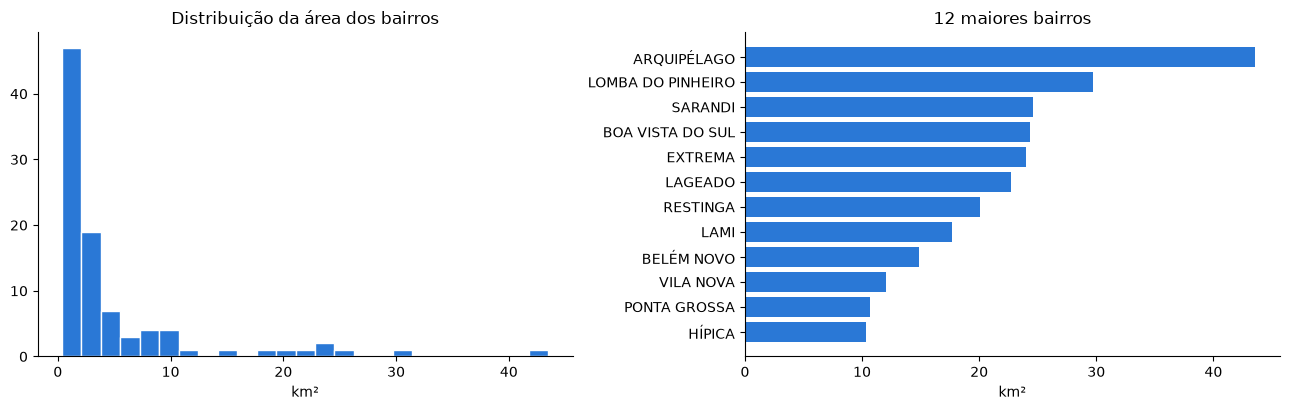

obliquidade: 2.92
curtose:     9.7


In [13]:
fig, eixos = plt.subplots(1, 2, figsize=(13, 4.2))

eixos[0].hist(bairros["area_km2"], bins=25, color="#2a78d6", edgecolor="white")
eixos[0].set_title("Distribuição da área dos bairros")
eixos[0].set_xlabel("km²")

top = bairros.nlargest(12, "area_km2").sort_values("area_km2")
eixos[1].barh(top["nome"], top["area_km2"], color="#2a78d6")
eixos[1].set_title("12 maiores bairros")
eixos[1].set_xlabel("km²")

for e in eixos:
    e.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

print("obliquidade:", round(bairros["area_km2"].skew(), 2))
print("curtose:    ", round(bairros["area_km2"].kurtosis(), 2))

In [14]:
# Compacidade de Polsby-Popper: 4·pi·A / P². Dá 1 no círculo e cai conforme a
# forma se alonga. Serve para achar quem vai ficar ilegível no mapa.
bairros["compacidade"] = (4 * 3.141592653589793 * (bairros["area_km2"] * 1e6)
                          / (bairros["perimetro_km"] * 1000) ** 2)

print("Cinco formas mais alongadas:")
print(bairros.nsmallest(5, "compacidade")[["nome", "area_km2", "compacidade"]]
      .round(3).to_string(index=False))

Cinco formas mais alongadas:
          nome  area_km2  compacidade
   ARQUIPÉLAGO    43.510        0.022
          LAMI    17.715        0.177
 PEDRA REDONDA     0.666        0.181
PRAIA DE BELAS     2.573        0.212
    BELÉM NOVO    14.855        0.228


---
# PARTE 2 — POAGEODATA

São quatro GeoPackages separados, não quatro camadas de um arquivo só. Todos em
SIRGAS 2000 / UTM 22S, com a mesma geometria por bairro e tabelas de atributos
diferentes.

## 2.1 O que tem dentro

In [15]:
POA = Path("dados/originais/poageodata")
ARQS = {
    "basico": "POA_bairros_basico_SIRGAS2000_22S.gpkg",
    "demografia_simplificada": "POA_bairros_demografia_simplificada_SIRGAS2000_22S.gpkg",
    "demografia_expandida": "POA_bairros_demografia_expandida_SIRGAS2000_22S.gpkg",
    "mortalidade": "POA_bairros_mortalidade_SIRGAS2000_22S.gpkg",
}

for apelido, nome in ARQS.items():
    caminho = POA / nome
    if not caminho.exists():
        print(f"{apelido:<26} AUSENTE — rode scripts/coleta_bairros.py")
        continue
    try:
        camadas = gpd.list_layers(caminho)["name"].tolist()
    except AttributeError:                      # geopandas < 1.0
        import fiona
        camadas = fiona.listlayers(caminho)
    print(f"{apelido:<26} {caminho.stat().st_size/1e6:>5.1f} MB  camadas: {camadas}")

basico                       5.8 MB  camadas: ['POA_bairros_basico_SIRGAS2000_22S']
demografia_simplificada      5.8 MB  camadas: ['POA_bairros_demografia_simplificada_SIRGAS2000_22S']
demografia_expandida         5.8 MB  camadas: ['POA_bairros_demografia_expandida_SIRGAS2000_22S']
mortalidade                  5.8 MB  camadas: ['POA_bairros_mortalidade_SIRGAS2000_22S']


In [16]:
poa = {}
for apelido, nome in ARQS.items():
    caminho = POA / nome
    if caminho.exists():
        poa[apelido] = gpd.read_file(caminho)
        print(f"{apelido:<26} {poa[apelido].shape}  CRS {poa[apelido].crs.to_epsg()}")

basico                     (94, 5)  CRS 31982
demografia_simplificada    (94, 29)  CRS 31982
demografia_expandida       (94, 105)  CRS 31982
mortalidade                (94, 22)  CRS 31982


In [17]:
# A página do Zenodo descreve as variáveis em prosa e não lista os campos.
# Tudo daqui para baixo depende do que aparecer nesta lista.
for apelido, gdf in poa.items():
    print(f"\n=== {apelido} ({len(gdf.columns)} colunas)")
    print([c for c in gdf.columns if c != "geometry"])


=== basico (5 colunas)
['cod_ibge', 'nome_ibge', 'nome_pmpa', 'nome_pmpa_sim']

=== demografia_simplificada (29 colunas)
['cod_ibge', 'nome_ibge', 'nome_pmpa', 'nome_pmpa_sim', 'pop_2022', 'pop_2022_pct', 'pop_masc', 'pop_fem', 'pop_masc_pct', 'pop_fem_pct', 'pop_0a14', 'pop_15a29', 'pop_30a59', 'pop_60mais', 'pop_0a14_pct', 'pop_15a29_pct', 'pop_30a59_pct', 'pop_60mais_pct', 'pop_branco', 'pop_preto', 'pop_amarelo', 'pop_pardo', 'pop_indigena', 'pop_branco_pct', 'pop_preto_pct', 'pop_amarelo_pct', 'pop_pardo_pct', 'pop_indigena_pct']

=== demografia_expandida (105 colunas)
['cod_ibge', 'nome_ibge', 'nome_pmpa', 'nome_pmpa_sim', 'pop_2022', 'pop_2022_pct', 'pop_masc', 'pop_fem', 'pop_masc_pct', 'pop_fem_pct', 'pop_0a14', 'pop_15a29', 'pop_30a59', 'pop_60mais', 'pop_0a14_pct', 'pop_15a29_pct', 'pop_30a59_pct', 'pop_60mais_pct', 'masc_0a14', 'masc_15a29', 'masc_30a59', 'masc_60mais', 'masc_0a14_pct', 'masc_15a29_pct', 'masc_30a59_pct', 'masc_60mais_pct', 'fem_0a14', 'fem_15a29', 'fem_30

## 2.2 As três grafias de nome

É o que torna esta base valiosa para o projeto. O POAGEODATA carrega, na mesma
linha, o código e o nome do IBGE, o nome que a Prefeitura usa no ObservaPOA e o
nome usado no sistema de mortalidade. Isso é a pedra de Roseta entre as fontes
do grupo — e é o que evita que cada integrante invente a sua própria tabela
de-para.

A célula abaixo tenta identificar as colunas pelo nome. **Confira a saída e
corrija o dicionário à mão se a heurística errar**; o resto do notebook usa
esses nomes.

In [18]:
basico = poa["basico"]

def achar(gdf, *pistas):
    for c in gdf.columns:
        alvo = normaliza(c)
        if all(normaliza(p) in alvo for p in pistas):
            return c
    return None

COLS = {
    "cod_ibge": (achar(basico, "cod") or achar(basico, "codigo")
                 or achar(basico, "cd")),
    "nome_ibge": achar(basico, "nome", "ibge") or achar(basico, "nm", "ibge"),
    "nome_pmpa": (achar(basico, "nome", "pmpa") or achar(basico, "nome", "observa")
                  or achar(basico, "nm", "pmpa")),
    "nome_sim": achar(basico, "nome", "sim") or achar(basico, "nm", "sim"),
}
print("Heurística encontrou:")
for k, v in COLS.items():
    print(f"  {k:<10} -> {v}")
print("\nTodas as colunas disponíveis:")
print([c for c in basico.columns if c != "geometry"])

Heurística encontrou:
  cod_ibge   -> cod_ibge
  nome_ibge  -> nome_ibge
  nome_pmpa  -> nome_pmpa
  nome_sim   -> nome_pmpa_sim

Todas as colunas disponíveis:
['cod_ibge', 'nome_ibge', 'nome_pmpa', 'nome_pmpa_sim']


In [19]:
# Se a heurística errou, corrija aqui e rode de novo a partir desta célula.
# COLS["nome_pmpa"] = "nome_da_coluna_correta"

faltando = [k for k, v in COLS.items() if v is None]
if faltando:
    raise ValueError(f"não identifiquei as colunas: {faltando} — preencha à mão")

nomes = basico[[COLS["cod_ibge"], COLS["nome_ibge"],
                COLS["nome_pmpa"], COLS["nome_sim"]]].copy()
nomes.columns = ["cod_ibge", "nome_ibge", "nome_pmpa", "nome_sim"]

divergem = nomes[(nomes["nome_ibge"] != nomes["nome_pmpa"])
                 | (nomes["nome_pmpa"] != nomes["nome_sim"])]
print(f"{len(divergem)} de {len(nomes)} bairros têm grafia diferente entre as fontes\n")
divergem.head(25)

94 de 94 bairros têm grafia diferente entre as fontes



,cod_ibge,nome_ibge,nome_pmpa,nome_sim
0,4314902078,Mário Quintana,MÁRIO QUINTANA,MARIO QUINTANA
1,4314902041,Moinhos de Vento,MOINHOS DE VENTO,MOINHOS VENTO
2,4314902037,Belém Velho,BELÉM VELHO,BELEM VELHO
3,4314902023,Camaquã,CAMAQUÃ,CAMAQUA
4,4314902089,Jardim Leopoldina,JARDIM LEOPOLDINA,JARDIM LEOPOLDINA
5,4314902090,Jardim Sabará,JARDIM SABARÁ,JARDIM SABARA
6,4314902015,Partenon,PARTENON,PARTENON
7,4314902075,Serraria,SERRARIA,SERRARIA
8,4314902091,Morro Santana,MORRO SANTANA,MORRO SANTANA
9,4314902004,Menino Deus,MENINO DEUS,MENINO DEUS


In [20]:
for c in ["nome_ibge", "nome_pmpa", "nome_sim"]:
    nomes[f"k_{c}"] = nomes[c].map(normaliza)
    nomes[f"f_{c}"] = nomes[c].map(chave_forte)

# A comparação usa chave_forte porque diferença de espaço ("PASSO D AREIA"
# contra "PASSO DAREIA") é grafia, não nome diferente. Com a chave normal esses
# casos iam parar na lista de decisão manual sem precisar.
so_grafia = ((nomes["f_nome_ibge"] == nomes["f_nome_pmpa"])
             & (nomes["f_nome_pmpa"] == nomes["f_nome_sim"]))

print(f"resolvidos pela normalização: {so_grafia.sum()}")
print(f"divergência real de nome:     {(~so_grafia).sum()}\n")

if (~so_grafia).any():
    print("Os que precisam de tabela de equivalência manual:")
    print(nomes.loc[~so_grafia, ["nome_ibge", "nome_pmpa", "nome_sim"]]
          .to_string(index=False))

resolvidos pela normalização: 88
divergência real de nome:     6

Os que precisam de tabela de equivalência manual:
              nome_ibge            nome_pmpa       nome_sim
       Moinhos de Vento     MOINHOS DE VENTO  MOINHOS VENTO
       Jardim São Pedro     JARDIM SÃO PEDRO  JAR SAO PEDRO
Coronel Aparício Borges CEL. APARICIO BORGES  CEL AP BORGES
      Lomba do Pinheiro    LOMBA DO PINHEIRO LOMBA PINHEIRO
       Centro Histórico     CENTRO HISTÓRICO         CENTRO
     Chácara das Pedras   CHÁCARA DAS PEDRAS CHACARA PEDRAS


## 2.3 Demografia: as contas fecham?

Duas conferências baratas que pegam a maioria dos problemas: a população somada
bate com o Censo, e as proporções somam 1 dentro de cada bairro.

In [21]:
demo = poa["demografia_simplificada"]
# No POAGEODATA a população total é "pop_2022" — não há "total" no nome.
col_pop = (achar(demo, "pop", "total") or achar(demo, "populacao")
           or ("pop_2022" if "pop_2022" in demo.columns else None))
if col_pop is None:
    raise KeyError(f"coluna de população não encontrada: {list(demo.columns)}")
print("coluna de população total:", col_pop)

total = demo[col_pop].sum()
print(f"\nsoma da população por bairro: {total:,.0f}".replace(",", "."))
print("Censo 2022, município:        1.332.845")
print(f"diferença:                    {total - 1_332_845:+,.0f}".replace(",", "."))

coluna de população total: pop_2022

soma da população por bairro: 1.332.845
Censo 2022, município:        1.332.845
diferença:                    +0


In [22]:
# As proporções precisam somar 1 dentro de cada grupo. Se não somarem, ou há
# categoria faltando ou a proporção foi calculada sobre outro denominador.
def colunas_de_proporcao(gdf, *pistas):
    """Só colunas de proporção (sufixo _pct no POAGEODATA). Sem esse filtro,
    uma coluna de contagem como pop_0a14 entra na soma e o total passa de 1."""
    return [c for c in gdf.columns
            if "PCT" in normaliza(c)
            and any(normaliza(p) in normaliza(c) for p in pistas)]

grupos = {
    "sexo": colunas_de_proporcao(demo, "MASC", "FEM", "HOM", "MULH"),
    "faixa etária": colunas_de_proporcao(demo, "0A14", "15A29", "30A59", "60MAIS"),
    "cor ou raça": colunas_de_proporcao(demo, "BRANC", "PRET", "AMAREL",
                                        "PARD", "INDIGEN"),
}
for rotulo, cols in grupos.items():
    if not cols:
        print(f"{rotulo:<14} nenhuma coluna identificada — confira a lista de 2.1")
        continue
    soma = demo[cols].sum(axis=1)
    print(f"{rotulo:<14} {len(cols)} colunas | soma por bairro: "
          f"min {soma.min():.3f}  máx {soma.max():.3f}")

sexo           2 colunas | soma por bairro: min 0.893  máx 1.000
faixa etária   4 colunas | soma por bairro: min 0.893  máx 1.000
cor ou raça    5 colunas | soma por bairro: min 0.892  máx 1.000


In [23]:
print("Nulos no arquivo de demografia:")
nulos = demo.isna().sum()
print(nulos[nulos > 0].to_string() if (nulos > 0).any() else "  nenhum")

if col_pop:
    zerados = demo[demo[col_pop] == 0]
    print(f"\nbairros com população zero: {len(zerados)}")
    if len(zerados):
        print(zerados[[COLS['nome_pmpa'], col_pop]].to_string(index=False))

Nulos no arquivo de demografia:
  nenhum

bairros com população zero: 0


## 2.4 Mortalidade

A base traz óbitos totais e por quatro grupos de doenças crônicas, com taxa já
calculada. Recalcular a taxa a partir de óbitos e população é a forma de
descobrir qual denominador o autor usou — e se ele é o mesmo que está no arquivo
de demografia.

In [24]:
mort = poa["mortalidade"]
print([c for c in mort.columns if c != "geometry"])

col_ob = achar(mort, "obito", "total") or achar(mort, "obitos")
col_tx = achar(mort, "taxa")
print(f"\nóbitos: {col_ob}   taxa: {col_tx}")

['cod_ibge', 'nome_ibge', 'nome_pmpa', 'nome_pmpa_sim', 'pop_2022', 'pop_2022_pct', 'obitos_2022', 'obitos_2022_pct', 'mort_2022_taxa_1k', 'obitos_circ_2022', 'mort_2022_circ_10k', 'mort_2022_circ_pct', 'obitos_diab_2022', 'mort_2022_diab_10k', 'mort_2022_diab_pct', 'obitos_neop_2022', 'mort_2022_neop_10k', 'mort_2022_neop_pct', 'obitos_resp_2022', 'mort_2022_resp_10k', 'mort_2022_resp_pct']

óbitos: obitos_2022   taxa: mort_2022_taxa_1k


In [25]:
if col_ob and col_tx:
    chk = mort[[COLS["nome_pmpa"], col_ob, col_tx]].copy()
    chk.columns = ["bairro", "obitos", "taxa_arquivo"]
    chk["k"] = chk["bairro"].map(normaliza)

    base_pop = demo[[COLS["nome_pmpa"], col_pop]].copy()
    base_pop.columns = ["bairro", "pop"]
    base_pop["k"] = base_pop["bairro"].map(normaliza)

    chk = chk.merge(base_pop[["k", "pop"]], on="k", how="left")
    chk["taxa_mil"] = 1000 * chk["obitos"] / chk["pop"]
    chk["dif"] = (chk["taxa_mil"] - chk["taxa_arquivo"]).abs()

    print("Diferença entre a taxa recalculada por mil e a do arquivo:")
    print(chk["dif"].describe().round(4).to_string())
    print("\nMaiores diferenças:")
    print(chk.nlargest(5, "dif")[["bairro", "obitos", "pop",
                                  "taxa_arquivo", "taxa_mil"]]
          .round(3).to_string(index=False))

Diferença entre a taxa recalculada por mil e a do arquivo:
count    94.0
mean      0.0
std       0.0
min       0.0
25%       0.0
50%       0.0
75%       0.0
max       0.0

Maiores diferenças:
        bairro  obitos   pop  taxa_arquivo  taxa_mil
VILA CONCEIÇÃO      18   969        18.576    18.576
TRÊS FIGUEIRAS      68  4016        16.932    16.932
   FARROUPILHA      17   774        21.964    21.964
      ANCHIETA      19   791        24.020    24.020
   BELÉM VELHO     125 10893        11.475    11.475


---
# PARTE 3 — A ligação

É aqui que as duas bases servem ao projeto. Três junções, nesta ordem: a malha
com o POAGEODATA, e as duas com os 94 nomes do `data.json` do INCT.

## 3.1 Malha × POAGEODATA

In [26]:
bairros["k"] = bairros["nome"].map(normaliza)
basico["k_pmpa"] = basico[COLS["nome_pmpa"]].map(normaliza)

set_malha = set(bairros["k"])
set_poa = set(basico["k_pmpa"])

print(f"malha:      {len(set_malha)} chaves")
print(f"POAGEODATA: {len(set_poa)} chaves")
print(f"casam:      {len(set_malha & set_poa)}")
print(f"\nsó na malha ({len(set_malha - set_poa)}): {sorted(set_malha - set_poa)}")
print(f"só no POAGEODATA ({len(set_poa - set_malha)}): {sorted(set_poa - set_malha)}")

malha:      94 chaves
POAGEODATA: 94 chaves
casam:      94

só na malha (0): []
só no POAGEODATA (0): []


In [27]:
def quase(a, b):
    """Pares que não casam pela chave, mas casam se eu ignorar o espaço."""
    fa = {chave_forte(x): x for x in a}
    fb = {chave_forte(x): x for x in b}
    return [(fa[k], fb[k]) for k in set(fa) & set(fb) if fa[k] != fb[k]]


pares = quase(set_malha - set_poa, set_poa - set_malha)
if pares:
    print("Casam ignorando espaço — conferir um a um antes de aceitar:")
    for x, y in pares:
        print(f"  {x!r:<28} ~ {y!r}")
else:
    print("Nenhum quase-caso por diferença de espaço.")

Nenhum quase-caso por diferença de espaço.


## 3.2 O `data.json` do INCT

Este é o arquivo que o grupo vai usar na tela do mapa. Ele traz, para cada
nível de água de 3,0 m a 10,0 m de 10 em 10 centímetros, quantos prédios e
quantas pessoas cada bairro perde.

Duas perguntas aqui. A primeira é a que importa para a junção: **esses nomes
correspondem aos 94 bairros oficiais?** Se não corresponderem, o mapa fica com
buraco e ninguém percebe até a apresentação. A segunda apareceu no caminho e é
mais séria: dois dos cinco campos do arquivo não são medida, são conta feita
sobre um número arredondado.

In [28]:
CAMINHO_INCT = Path("dados/originais/data.json")

if not CAMINHO_INCT.exists():
    print(f"{CAMINHO_INCT} não encontrado — pule esta seção.")
    inct = None
else:
    inct = json.loads(CAMINHO_INCT.read_text(encoding="utf-8"))

    # Três camadas de aninhamento: nível de água, bairro, métrica. O nome do
    # bairro é a CHAVE do dicionário, não o valor de um campo "nome" — isso
    # muda como se extrai a lista.
    niveis_inct = sorted(inct, key=lambda k: float(k.rstrip("m").replace("_", ".")))
    nomes_inct = set(inct[niveis_inct[0]])

    print(f"níveis: {len(niveis_inct)}  de {niveis_inct[0]} a {niveis_inct[-1]}")
    print(f"bairros por nível: {sorted({len(v) for v in inct.values()})}")
    print(f"métricas: {sorted(next(iter(inct[niveis_inct[0]].values())))}")
    print(f"\nlinhas se virar tabela: {len(niveis_inct)} x {len(nomes_inct)} = "
          f"{len(niveis_inct) * len(nomes_inct)}")

níveis: 71  de 3_0m a 10_0m
bairros por nível: [94]
métricas: ['affected_buildings', 'affected_population', 'percentage', 'population', 'total_buildings']

linhas se virar tabela: 71 x 94 = 6674


### Os nomes casam?

A malha da Prefeitura escreve em maiúscula, o `data.json` em caixa de título.
Zero nomes idênticos byte a byte entre as duas — a normalização não é refinamento,
é condição para a junção existir.

In [29]:
if inct is not None:
    k_inct = {normaliza(n): n for n in nomes_inct}

    print(f"idênticos byte a byte à malha: "
          f"{len(nomes_inct & set(bairros['nome']))} de {len(nomes_inct)}")
    print(f"casam pela chave normalizada:   {len(set(k_inct) & set_malha)} de {len(nomes_inct)}")

    sobra_inct = sorted(k_inct[k] for k in set(k_inct) - set_malha)
    sobra_malha = sorted(set_malha - set(k_inct))
    print(f"\nsó no data.json: {sobra_inct}")
    print(f"só na malha:     {sobra_malha}")

    # E contra o POAGEODATA, que escreve nome_ibge na mesma caixa do data.json.
    nomes_poa_ibge = set(basico[COLS["nome_ibge"]])
    print(f"\nidênticos byte a byte ao nome_ibge do POAGEODATA: "
          f"{len(nomes_inct & nomes_poa_ibge)} de {len(nomes_inct)}")
    print(f"  divergem: {sorted(nomes_inct - nomes_poa_ibge)} "
          f"vs {sorted(nomes_poa_ibge - nomes_inct)}")

idênticos byte a byte à malha: 0 de 94
casam pela chave normalizada:   92 de 94

só no data.json: ['Coronel Aparício Borges', "Passo D'Areia"]
só na malha:     ['CEL APARICIO BORGES', 'PASSO DA AREIA']

idênticos byte a byte ao nome_ibge do POAGEODATA: 93 de 94
  divergem: ["Passo D'Areia"] vs ['Passo da Areia']


93 de 94 nomes do `data.json` são idênticos, caractere por caractere, ao
`nome_ibge` do POAGEODATA. Isso diz de onde o INCT tirou a nomenclatura: do
IBGE, não da Prefeitura. Útil saber — quem for cruzar com o `data.json` deve
partir do `nome_ibge`, que casa quase sem tratamento, e não do nome municipal.

Sobram dois nomes que nenhuma normalização resolve, porque a diferença não é
de grafia e sim de palavra: `Coronel` abreviado como `Cel.` na malha, e
`Passo D'Areia` contra `Passo da Areia`. Esses vão para um dicionário à mão.

In [30]:
# Dois casos, mapeados para a forma do IBGE, que é o destino comum.
APELIDOS = {
    "CORONEL APARICIO BORGES": "CEL APARICIO BORGES",
    "PASSO D AREIA": "PASSO DA AREIA",
    "PASSO DAREIA": "PASSO DA AREIA",
}


def chave_inct(nome):
    """Chave de junção que resolve também os apelidos, não só a grafia."""
    k = normaliza(nome)
    if k is None:
        return None
    return APELIDOS.get(k, k).replace(" ", "")


if inct is not None:
    c_inct = {chave_inct(n) for n in nomes_inct}
    c_malha = {chave_inct(n) for n in bairros["nome"]}
    c_poa = {chave_inct(n) for n in basico[COLS["nome_pmpa"]]}

    print(f"data.json x malha:      {len(c_inct & c_malha)} de 94")
    print(f"data.json x POAGEODATA: {len(c_inct & c_poa)} de 94")
    print(f"nas três bases:         {len(c_inct & c_malha & c_poa)} de 94")

data.json x malha:      94 de 94
data.json x POAGEODATA: 94 de 94
nas três bases:         94 de 94


### O problema que não era da junção

Com os nomes resolvidos, dei uma olhada nos valores. Duas coisas não fecham.

`percentage` está arredondado **para cima** em todas as 6.674 linhas, sem
exceção. Parece detalhe até ver o efeito nos bairros pouco atingidos: Santa
Tereza em 3,2 m tem 1 prédio afetado em 15.906, o que dá 0,006%, e o campo diz
1%. É 159 vezes o valor real.

Pior: `affected_population` não é contagem de pessoas. Todas as 6.674 linhas
são exatamente `percentage / 100 * population` — a população afetada foi
derivada da proporção já arredondada. Então ela herda o viés e, além disso, só
se move em degraus de 1% da população do bairro.

In [31]:
if inct is not None:
    import math

    conferencia = {"pct_ceil": 0, "pct_outro": 0,
                   "pop_derivada": 0, "pop_independente": 0}
    for nv in niveis_inct:
        for m in inct[nv].values():
            razao = m["affected_buildings"] / m["total_buildings"] * 100
            if m["percentage"] == math.ceil(razao):
                conferencia["pct_ceil"] += 1
            else:
                conferencia["pct_outro"] += 1

            est = m["percentage"] / 100 * m["population"]
            if m["affected_population"] in (round(est), math.ceil(est),
                                            math.floor(est)):
                conferencia["pop_derivada"] += 1
            else:
                conferencia["pop_independente"] += 1

    total = len(niveis_inct) * len(nomes_inct)
    print(f"percentage == ceil(afetados / total * 100): "
          f"{conferencia['pct_ceil']} de {total}")
    print(f"affected_population == f(percentage, population): "
          f"{conferencia['pop_derivada']} de {total}")

    # A granularidade perdida, vista em um bairro
    s_pred = {inct[nv]["Santa Tereza"]["affected_buildings"] for nv in niveis_inct}
    s_pop = {inct[nv]["Santa Tereza"]["affected_population"] for nv in niveis_inct}
    print(f"\nSanta Tereza ao longo dos 71 níveis:")
    print(f"  prédios afetados:  {len(s_pred)} valores distintos")
    print(f"  pessoas afetadas:  {len(s_pop)} valores distintos -> {sorted(s_pop)}")
    print(f"  (população do bairro: "
          f"{inct[niveis_inct[0]]['Santa Tereza']['population']:,})")

percentage == ceil(afetados / total * 100): 6674 de 6674
affected_population == f(percentage, population): 6674 de 6674

Santa Tereza ao longo dos 71 níveis:
  prédios afetados:  50 valores distintos
  pessoas afetadas:  3 valores distintos -> [0, 314, 628]
  (população do bairro: 31,358)


### Monotonicidade: água subindo não desafeta ninguém

É a checagem que uma simulação de alagamento tem que passar. Quatro bairros
falham, e falham de três maneiras diferentes — o que importa, porque cada uma
pede um tratamento diferente.

In [32]:
if inct is not None:
    quebras = {}
    for nome in nomes_inct:
        serie = [inct[nv][nome]["affected_buildings"] for nv in niveis_inct]
        tot = inct[niveis_inct[0]][nome]["total_buildings"]
        q = [(niveis_inct[i - 1], serie[i - 1], niveis_inct[i], serie[i])
             for i in range(1, len(serie)) if serie[i] < serie[i - 1]]
        if q:
            quebras[nome] = (tot, q)

    for nome, (tot, q) in sorted(quebras.items()):
        print(f"{nome}  (total {tot:,} prédios, {len(q)} queda(s))")
        for a, va, b, vb in q:
            print(f"    {a:>6} = {va:>6,}  ->  {b:>6} = {vb:>6,}"
                  f"   ({(vb - va) / va * 100:+.1f}%)")

Arquipélago  (total 4,688 prédios, 6 queda(s))
      3_0m =  4,685  ->    3_1m =  4,680   (-0.1%)
      3_5m =  4,685  ->    3_6m =  4,680   (-0.1%)
      4_0m =  4,685  ->    4_1m =  4,674   (-0.2%)
      4_5m =  4,685  ->    4_6m =  4,680   (-0.1%)
      5_0m =  4,685  ->    5_1m =  4,680   (-0.1%)
      5_3m =  4,688  ->    5_4m =  4,680   (-0.2%)
Centro Histórico  (total 4,312 prédios, 1 queda(s))
      9_6m =  2,050  ->    9_7m =      0   (-100.0%)
Espírito Santo  (total 3,342 prédios, 3 queda(s))
      3_3m =    637  ->    3_4m =    633   (-0.6%)
      3_4m =    633  ->    3_5m =     25   (-96.1%)
      4_7m =  2,101  ->    4_8m =     47   (-97.8%)
Lageado  (total 3,637 prédios, 1 queda(s))
      8_0m =    108  ->    8_1m =      0   (-100.0%)
Rubem Berta  (total 6,565 prédios, 1 queda(s))
      8_7m =    252  ->    8_8m =      0   (-100.0%)


Três fenômenos distintos:

**Buraco** — Centro Histórico (9,7 e 9,8 m), Lageado (8,1 m) e Rubem Berta
(8,8 m) caem a zero e voltam ao normal no nível seguinte. Zero cercado de
valores positivos não é "não alagou", é dado que faltou. Interpolo entre os
vizinhos: a 10 cm de distância a curva é praticamente reta.

**Ruído de borda** — o Arquipélago oscila entre 4.674 e 4.688 prédios. São 14
prédios em 4.688, e o bairro já está 99,7% alagado desde 3,0 m. É imprecisão
de quem conta pixel na margem do polígono, não informação. Fica como está,
marcado.

**Defeito de outra natureza** — Espírito Santo tem um platô de 637 prédios nos
cinco primeiros níveis, despenca para 25 e só chega a 133 em 10,0 m, com um
pico isolado de 2.101 em 4,7 m. Não dá para adivinhar o número certo, e inventar
seria pior que marcar. Fica o valor original com bandeira de suspeito, e uma
pergunta para o INCT.

In [33]:
# A limpeza inteira está em scripts/limpeza_data_json.py, para não repetir
# aqui o que já é código testado. Rode uma vez e leia o resultado.
CAMINHO_LIMPO = Path("dados/processados/inct_niveis_bairro.csv")

if not CAMINHO_LIMPO.exists():
    print("rode:  python scripts/limpeza_data_json.py")
else:
    niveis_df = pd.read_csv(CAMINHO_LIMPO)
    print(f"{len(niveis_df)} linhas, {niveis_df['bairro'].nunique()} bairros\n")
    print("Classificação das linhas:")
    print(niveis_df["qualidade"].value_counts().to_string())

    print(f"\nO que os campos de origem inflavam:")
    for nv in (3.0, 5.0, 10.0):
        corte = niveis_df[niveis_df["nivel_m"] == nv]
        o, e = corte["affected_population"].sum(), corte["pop_afetada_est"].sum()
        print(f"  cidade em {nv:>4.1f} m: origem {o:>9,} | estimado {e:>9,} "
              f"({(o - e) / e * 100:+.1f}%)")

    display(niveis_df[niveis_df["bairro"] == "Centro Histórico"]
            .tail(6)[["nivel_origem", "affected_buildings", "pct_predios",
                      "percentage_origem", "pop_afetada_est",
                      "affected_population", "qualidade"]])

6674 linhas, 94 bairros

Classificação das linhas:
qualidade
ok                6658
ruido_borda          6
suspeito_plato       5
faltante             4
suspeito_pico        1

O que os campos de origem inflavam:
  cidade em  3.0 m: origem    34,605 | estimado    33,026 (+4.8%)
  cidade em  5.0 m: origem   127,611 | estimado   125,699 (+1.5%)
  cidade em 10.0 m: origem   274,993 | estimado   271,875 (+1.1%)


,nivel_origem,affected_buildings,pct_predios,percentage_origem,pop_afetada_est,affected_population,qualidade
1272,9_5m,2018,46.800,47,14306,14368,ok
1273,9_6m,2050,47.542,48,14533,14674,ok
1274,9_7m,2077,48.168,0,14724,14878,faltante
1275,9_8m,2103,48.771,0,14909,15081,faltante
1276,9_9m,2130,49.397,50,15100,15285,ok
1277,10_0m,2181,50.580,51,15462,15591,ok


## 3.3 A tabela de-para

O produto desta parte. Uma linha por bairro, com a chave, as grafias de cada
fonte e o código do IBGE. Qualquer integrante do grupo que precise juntar algo
por bairro passa a usar este arquivo em vez de normalizar por conta própria.

In [34]:
de_para = (bairros[["k", "nome", "area_km2"]]
           .rename(columns={"nome": "nome_prefeitura"})
           .merge(nomes.rename(columns={"k_nome_pmpa": "k"})
                       [["k", "cod_ibge", "nome_ibge", "nome_pmpa", "nome_sim"]],
                  on="k", how="outer", indicator=True))

# A chave que resolve os apelidos entra como coluna à parte: é ela que casa com
# o data.json, e quem for juntar as três bases precisa dela e não da chave de
# grafia.
de_para["chave_tres_bases"] = de_para["nome_prefeitura"].fillna(
    de_para["nome_ibge"]).map(chave_inct)

if inct is not None:
    por_chave = {chave_inct(n): n for n in nomes_inct}
    de_para["nome_inct"] = de_para["chave_tres_bases"].map(por_chave)
    faltam = de_para["nome_inct"].isna().sum()
    print(f"bairros sem nome correspondente no data.json: {faltam}")

print(de_para["_merge"].value_counts().to_string())
print("\nlinhas na tabela:", len(de_para), "(tem que ser 94)")

saida = Path("dados/processados")
saida.mkdir(parents=True, exist_ok=True)
de_para.drop(columns="_merge").to_csv(saida / "de_para_bairros.csv", index=False)
print(f"gravado: {saida / 'de_para_bairros.csv'}")
de_para.head(10)

bairros sem nome correspondente no data.json: 0
_merge
both          94
left_only      0
right_only     0

linhas na tabela: 94 (tem que ser 94)
gravado: dados/processados/de_para_bairros.csv


,k,nome_prefeitura,area_km2,cod_ibge,nome_ibge,nome_pmpa,nome_sim,_merge,chave_tres_bases,nome_inct
0,ABERTA DOS MORROS,ABERTA DOS MORROS,3.761359,4314902080,Aberta dos Morros,ABERTA DOS MORROS,ABERTA DOS MORROS,both,ABERTADOSMORROS,Aberta dos Morros
1,AGRONOMIA,AGRONOMIA,8.852881,4314902035,Agronomia,AGRONOMIA,AGRONOMIA,both,AGRONOMIA,Agronomia
2,ANCHIETA,ANCHIETA,9.167484,4314902055,Anchieta,ANCHIETA,ANCHIETA,both,ANCHIETA,Anchieta
3,ARQUIPELAGO,ARQUIPÉLAGO,43.510352,4314902033,Arquipélago,ARQUIPÉLAGO,ARQUIPELAGO,both,ARQUIPELAGO,Arquipélago
4,AUXILIADORA,AUXILIADORA,0.843628,4314902045,Auxiliadora,AUXILIADORA,AUXILIADORA,both,AUXILIADORA,Auxiliadora
5,AZENHA,AZENHA,1.387284,4314902008,Azenha,AZENHA,AZENHA,both,AZENHA,Azenha
6,BELA VISTA,BELA VISTA,1.023233,4314902043,Bela Vista,BELA VISTA,BELA VISTA,both,BELAVISTA,Bela Vista
7,BELEM NOVO,BELÉM NOVO,14.854655,4314902073,Belém Novo,BELÉM NOVO,BELEM NOVO,both,BELEMNOVO,Belém Novo
8,BELEM VELHO,BELÉM VELHO,9.599238,4314902037,Belém Velho,BELÉM VELHO,BELEM VELHO,both,BELEMVELHO,Belém Velho
9,BOA VISTA,BOA VISTA,1.686354,4314902056,Boa Vista,BOA VISTA,BOA VISTA,both,BOAVISTA,Boa Vista


---
# PARTE 4 — Exploração cruzada

Com as duas bases ligadas, aparecem perguntas que nenhuma delas responde
sozinha.

## 4.1 Densidade populacional

bairros cruzados: 94
count       94.0
mean      5715.0
std       4268.0
min         86.0
25%       2601.0
50%       5450.0
75%       7860.0
max      20526.0


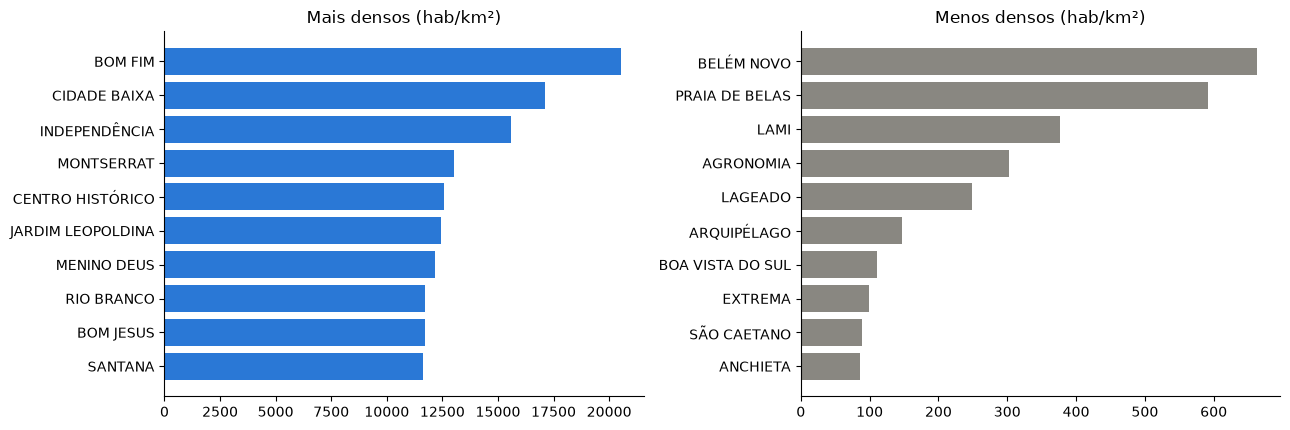

In [35]:
cruzado = (bairros[["k", "nome", "area_km2"]]
           .merge(demo.assign(k=demo[COLS["nome_pmpa"]].map(normaliza))
                      [["k", col_pop]], on="k", how="inner"))
cruzado["hab_km2"] = cruzado[col_pop] / cruzado["area_km2"]

print(f"bairros cruzados: {len(cruzado)}")
print(cruzado["hab_km2"].describe().round(0).to_string())

fig, eixos = plt.subplots(1, 2, figsize=(13, 4.4))
for eixo, (asc, titulo) in zip(eixos, [(False, "Mais densos"), (True, "Menos densos")]):
    t = cruzado.sort_values("hab_km2", ascending=asc).head(10).sort_values("hab_km2")
    eixo.barh(t["nome"], t["hab_km2"], color="#2a78d6" if not asc else "#898781")
    eixo.set_title(f"{titulo} (hab/km²)")
    eixo.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

A densidade é o que transforma "o bairro X foi atingido" em "tantas pessoas
foram atingidas por km² de mancha". Se o grupo for cruzar a mancha de 2024 do
Lucas com os bairros, é este o número que dá peso ao resultado.

In [36]:
# Parcela de 60+, não a contagem: o ranking é de proporção. No POAGEODATA a
# coluna é pop_60mais_pct. Quem tem mais dificuldade de sair numa evacuação.
col_60 = achar(demo, "60", "pct")
if col_60:
    idosos = (bairros[["k", "nome"]]
              .merge(demo.assign(k=demo[COLS["nome_pmpa"]].map(normaliza))
                         [["k", col_60, col_pop]], on="k", how="inner"))
    idosos = idosos.sort_values(col_60, ascending=False)
    print(f"coluna usada: {col_60}\n")
    print("Dez bairros com maior parcela de 60+:")
    print(idosos.head(10)[["nome", col_60, col_pop]].to_string(index=False))
else:
    print("não identifiquei a coluna de 60+; confira a lista de colunas em 2.1")

coluna usada: pop_60mais_pct

Dez bairros com maior parcela de 60+:
              nome  pop_60mais_pct  pop_2022
  MOINHOS DE VENTO        0.402101      9995
       FARROUPILHA        0.377261       774
    JARDIM LINDÓIA        0.328325      7587
        BELA VISTA        0.325747     11819
  JARDIM SÃO PEDRO        0.325602      3320
    VILA  ASSUNÇÃO        0.324610      3974
CHÁCARA DAS PEDRAS        0.324526      5639
       MENINO DEUS        0.319874     27961
     SANTA CECÍLIA        0.319181      4640
       AUXILIADORA        0.317207      8909


## 4.3 As três bases juntas

Aqui é onde a junção paga. O `data.json` diz quanto cada bairro alaga; o
POAGEODATA diz quem mora lá. Cruzando os dois, a pergunta deixa de ser "quais
bairros alagam" e passa a ser **quais bairros alagam cedo e têm população mais
difícil de evacuar** — que é uma pergunta de prioridade, não de geografia.

bairros com as três bases: 94 de 94
bairros já atingidos em 3,0 m: 24

Atingidos em 3,0 m, do maior para o menor em parcela de 60+:
          bairro  pct_predios  pop_afetada_est  pop_60mais_pct      qualidade
   Vila Assunção        7.874              313        0.324610             ok
        Tristeza        1.370              236        0.300738             ok
  Espírito Santo       19.060              944        0.294569 suspeito_plato
         Ipanema        0.258               35        0.284712             ok
     São Geraldo        1.012               70        0.278785             ok
        Floresta        0.536               47        0.278586             ok
  Vila Conceição        1.673               16        0.276574             ok
Centro Histórico        0.974              298        0.258105             ok
      Navegantes        7.519              249        0.253394             ok
  Praia de Belas       26.897              409        0.238502             ok


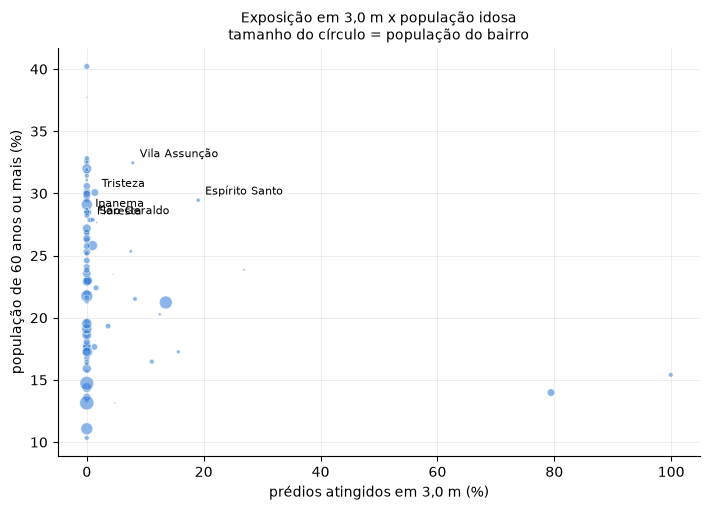

In [37]:
if inct is not None and CAMINHO_LIMPO.exists():
    # Corte em 3,0 m: o cenário mais baixo do arquivo e, por isso, o mais
    # provável de se repetir.
    corte = (niveis_df[niveis_df["nivel_m"] == 3.0]
             [["bairro", "chave", "pct_predios", "pop_afetada_est", "qualidade"]])

    perfil = demo.assign(chave=demo[COLS["nome_pmpa"]].map(chave_inct))
    colunas_perfil = ["chave", col_pop] + ([col_60] if col_60 else [])
    juntas = corte.merge(perfil[colunas_perfil], on="chave", how="inner")
    print(f"bairros com as três bases: {len(juntas)} de 94")

    atingidos = juntas[juntas["pct_predios"] > 0].copy()
    print(f"bairros já atingidos em 3,0 m: {len(atingidos)}")

    if col_60:
        # Ordena por parcela de idosos entre os que já alagam no nível mais baixo.
        atingidos = atingidos.sort_values(col_60, ascending=False)
        print(f"\nAtingidos em 3,0 m, do maior para o menor em parcela de 60+:")
        print(atingidos.head(10)[["bairro", "pct_predios", "pop_afetada_est",
                                  col_60, "qualidade"]].to_string(index=False))

        fig, eixo = plt.subplots(figsize=(7.2, 5.2))
        eixo.scatter(juntas["pct_predios"], juntas[col_60] * 100,
                     s=juntas[col_pop] / 600, alpha=0.55,
                     color="#2a78d6", edgecolor="white", linewidth=0.6)
        for _, r in atingidos.head(6).iterrows():
            eixo.annotate(r["bairro"], (r["pct_predios"], r[col_60] * 100),
                          fontsize=8, xytext=(5, 4), textcoords="offset points")
        eixo.set_xlabel("prédios atingidos em 3,0 m (%)")
        eixo.set_ylabel("população de 60 anos ou mais (%)")
        eixo.set_title("Exposição em 3,0 m x população idosa\n"
                       "tamanho do círculo = população do bairro", fontsize=10)
        eixo.grid(alpha=0.25, linewidth=0.6)
        for lado in ("top", "right"):
            eixo.spines[lado].set_visible(False)
        plt.tight_layout()
        plt.show()

---
# O que esta exploração entrega na análise

1. **`dados/processados/de_para_bairros.csv`** — a correspondência entre a
   malha da Prefeitura, as três grafias do POAGEODATA, o nome do INCT e o
   código do IBGE. É o que impede cada um de inventar a própria normalização.
   A coluna `chave_tres_bases` é a que fecha 94/94, porque resolve também os
   dois apelidos.
2. **`dados/processados/inct_niveis_bairro.csv`** — a simulação do INCT em
   formato de tabela, 6.674 linhas, com a proporção recalculada, a população
   atingida reestimada e uma coluna `qualidade` que diz o que é dado bom, o que
   foi interpolado e o que está suspeito.
3. **A malha validada**, com área em km² calculada em UTM 22S, e não os graus
   quadrados que vêm no serviço, e com os 128 polígonos unidos nos 94 bairros
   que eles realmente são.
4. **Três avisos que mudam como usar o `data.json`**: `affected_population` é
   derivada de um percentual arredondado para cima e não serve como contagem
   de pessoas; quatro células estão com buraco; e o Espírito Santo tem seis
   valores que o INCT precisa explicar.